Throughout this notebook, we use \(D_1\) to denote the property that the sequential model stochastically dominates the static model in the number of occupied sites. And \(D_2\) to denote the property that the static model stochastically dominates the static model.


# Unfriendly Seating Process — Generalized Graph Model

This notebook illustrates the generalized (graph-based) unfriendly seating
process using three modules:

1. **Calc_PerGraph**: given a graph's adjacency matrix, computes the static
   and sequential occupied-count distributions and checks D_1 / D_2
   stochastic dominance for that single graph.
2. **Graph**: visualizes a graph together with every distinct blocking limit
   (final saturated state) reachable by the process.
3. **GeneralSearch**: scans all graphs on n vertices (optionally bounded by
   degree) to find the first one that fails a given dominance property.

First, a few example graphs are analyzed individually: a path graph, all
cycle graphs up to n=6, and a tree. Then GeneralSearch is used to confirm
D_1 holds across broader families of graphs.

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path
import pandas as pd

from IPython.display import display, HTML
from io import BytesIO
import base64


sys.path.append(str(Path.cwd().parent / "Source"))

from Calc_PerGraph import analyze_graph_dominance
from Graph import visualize_blocking_limits
from GeneralSearch import find_first_dominance_failure
from GeneralSearch import generate_symmetric_matrices


## Auxiliar functions to construct adyacence matrices and tables


In [11]:
def path_graph_matrix(n):
    
    matrix = [[0] * n for _ in range(n)]
    for i in range(n - 1):
        matrix[i][i + 1] = matrix[i + 1][i] = 1
    return matrix


def cycle_graph_matrix(n):
    
    matrix = [[0] * n for _ in range(n)]
    if n == 1:
        return matrix
    if n == 2:
        matrix[0][1] = matrix[1][0] = 1
        return matrix

    for i in range(n):
        j = (i + 1) % n
        matrix[i][j] = matrix[j][i] = 1
    return matrix


def compare_graphs_table(adjacency_matrices, graph_titles=None):
    
    if graph_titles is None:
        graph_titles = [
            f"Graph {i+1}" for i in range(len(adjacency_matrices))
        ]

    if len(graph_titles) != len(adjacency_matrices):
        raise ValueError(
            "There must be the same number of graph titles as adjacency matrices."
        )

    rows = []

    for i, adjacency_matrix in enumerate(adjacency_matrices):

        
        results = analyze_graph_dominance(adjacency_matrix)

        ks = results["ks"]
        cumulative_stat = results["cumulative_stat"]
        cumulative_seq = results["cumulative_seq"]
        dominance = results["stochastic_dominance"]

        
        fig = visualize_blocking_limits(
            adjacency_matrix,
            graph_title=graph_titles[i]
        )

        
        buffer = BytesIO()
        fig.savefig(
            buffer,
            format="png",
            dpi=120,
            bbox_inches="tight",
            facecolor=fig.get_facecolor()
        )
        buffer.seek(0)

        image_base64 = base64.b64encode(
            buffer.read()
        ).decode("utf-8")

        plt.close(fig)
        buffer.close()

        image_html = f"""
        <img src="data:image/png;base64,{image_base64}"
             style="width:180px; height:auto; border-radius:8px;">
        """

        rows.append({
            "Values of k": str(ks),
            "Graph": image_html,
            "CDF static": [
                round(float(x), 6) for x in cumulative_stat
            ],
            "CDF sequencial": [
                round(float(x), 6) for x in cumulative_seq
            ],
            "Stochastic dominance": dominance
        })

    df = pd.DataFrame(rows)

    
    html = df.to_html(
        index=False,
        escape=False,
        border=0,
        justify="center"
    )

    styled_html = f"""
    <style>
        .graph-table {{
            width: 100%;
            border-collapse: collapse;
            font-family: Arial, sans-serif;
            font-size: 13px;
            text-align: center;
            background-color: #ffffff;
        }}

        .graph-table th {{
            background-color: #263449;
            color: white;
            padding: 14px;
            border: 1px solid #44546a;
        }}

        .graph-table td {{
            padding: 12px;
            border: 1px solid #dce1e8;
            vertical-align: middle;
        }}

        .graph-table tr:nth-child(even) {{
            background-color: #f1f5f9;
        }}

        .graph-table tr:hover {{
            background-color: #e2eaf3;
        }}
    </style>

    <div style="width:100%; overflow-x:auto;">
        {html.replace('<table border="0" class="dataframe">',
                      '<table class="graph-table">')}
    </div>
    """

    display(HTML(styled_html))

    return df



## Cycle graphs, n = 1 to 6

Values of k,Graph,CDF static,CDF sequencial,Stochastic dominance
[1],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).
[2],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).
[2],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).
"[2, 3]",\n \n,"[0.6, 1.0]","[0.333333, 1.0]",D_1 holds: the sequential model dominates the static model.

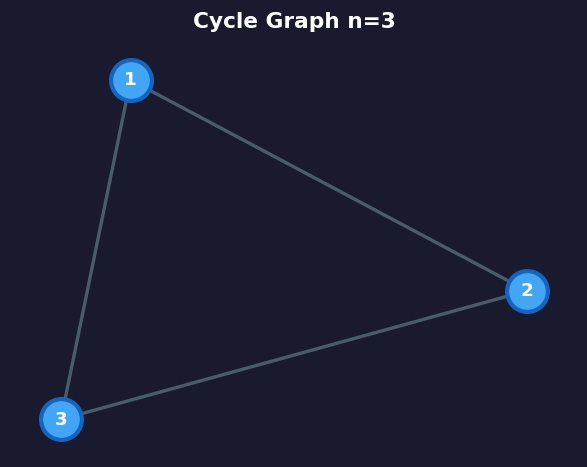
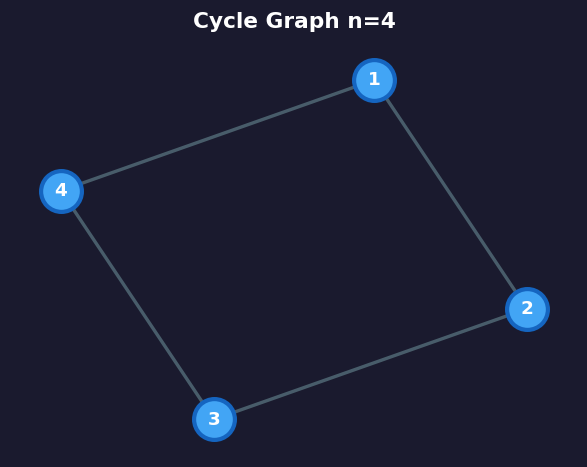
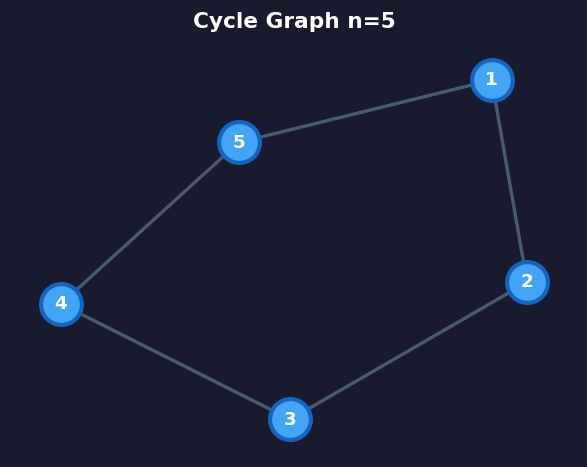
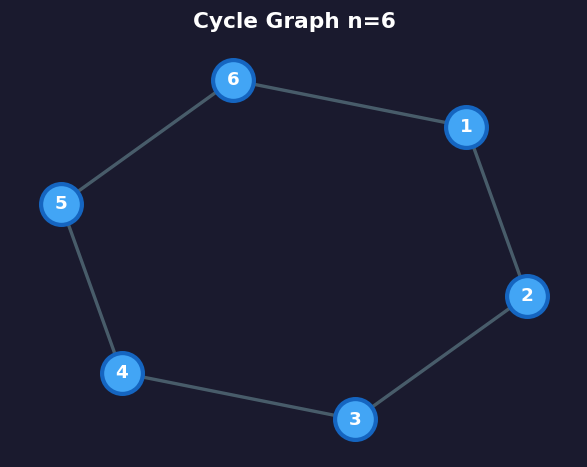

In [12]:
cycle_matrix = []
for n in range(3, 7):
    cycle_matrix.append(cycle_graph_matrix(n))

df = compare_graphs_table(cycle_matrix, graph_titles=[f"Cycle Graph n={n}" for n in range(3, 7)])


## General search: D_1 across all graphs up to n = 5

Checks, for every n from 1 to 5, whether any connected graph on n vertices
fails D_1. If `find_first_dominance_failure` returns `None` for every n,
D_1 holds across the entire family.

n = 1: D_1 holds for every graph (1 graphs analyzed).


Values of k,Graph,CDF static,CDF sequencial,Stochastic dominance
[1],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).

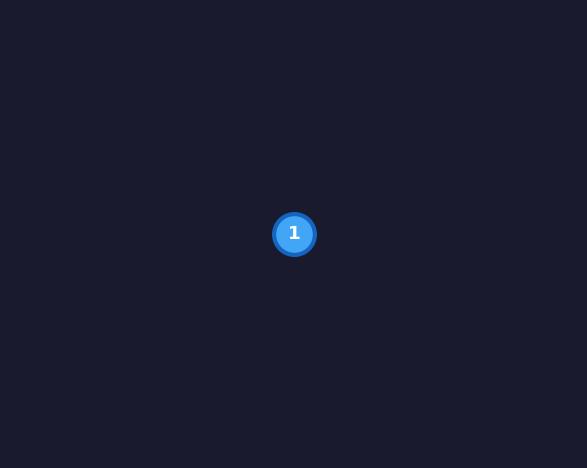

n = 2: D_1 holds for every graph (1 graphs analyzed).


Values of k,Graph,CDF static,CDF sequencial,Stochastic dominance
[1],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).

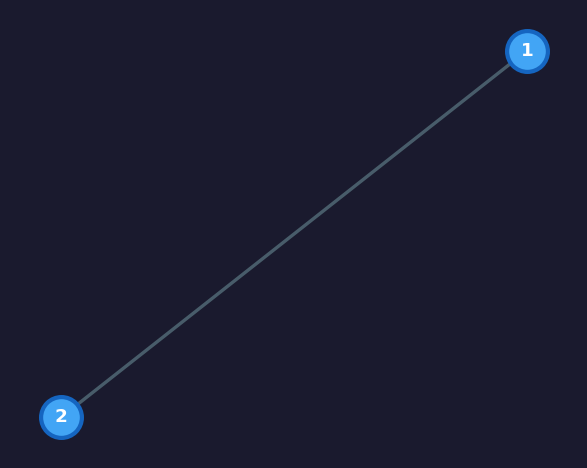

n = 3: D_1 holds for every graph (2 graphs analyzed).


Values of k,Graph,CDF static,CDF sequencial,Stochastic dominance
"[1, 2]",\n \n,"[0.5, 1.0]","[0.333333, 1.0]",D_1 holds: the sequential model dominates the static model.
[1],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).

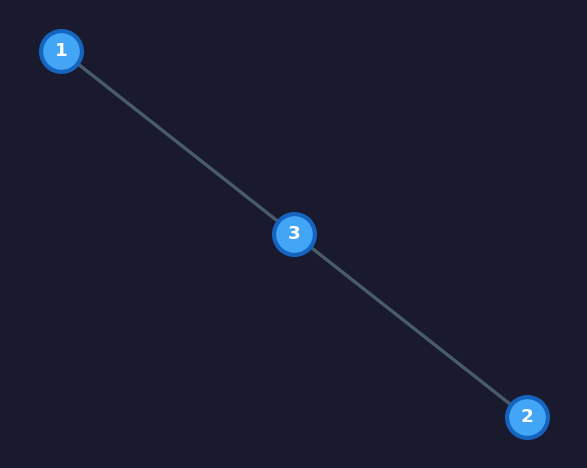
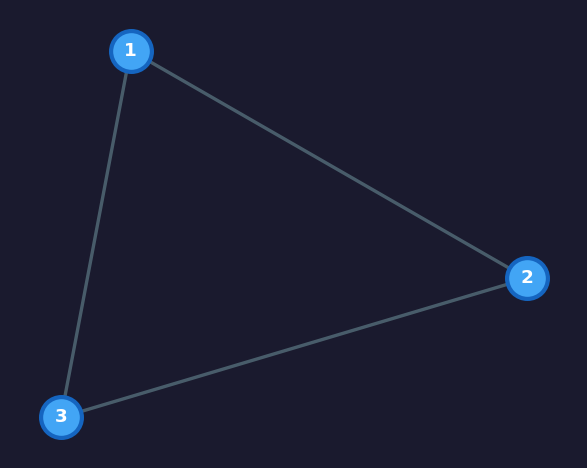

n = 4: D_1 holds for every graph (6 graphs analyzed).


Values of k,Graph,CDF static,CDF sequencial,Stochastic dominance
"[1, 3]",\n \n,"[0.5, 1.0]","[0.25, 1.0]",D_1 holds: the sequential model dominates the static model.
[2],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).
"[1, 2]",\n \n,"[0.333333, 1.0]","[0.25, 1.0]",D_1 holds: the sequential model dominates the static model.
[2],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).
"[1, 2]",\n \n,"[0.666667, 1.0]","[0.5, 1.0]",D_1 holds: the sequential model dominates the static model.
[1],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).

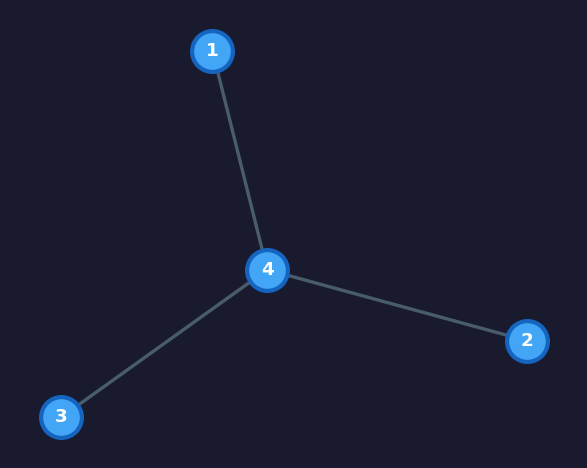
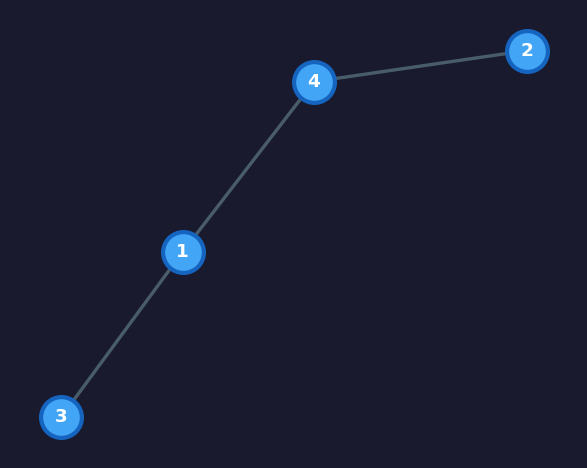
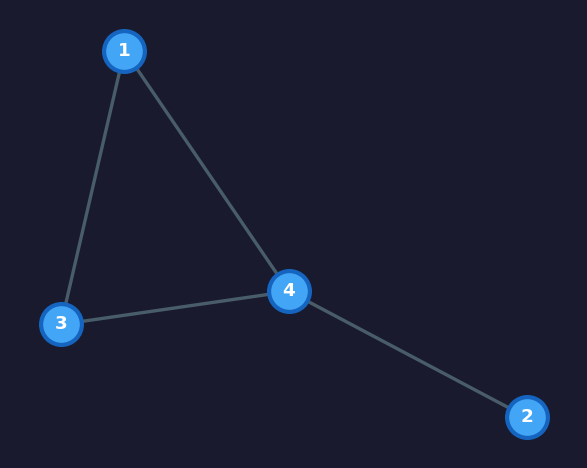
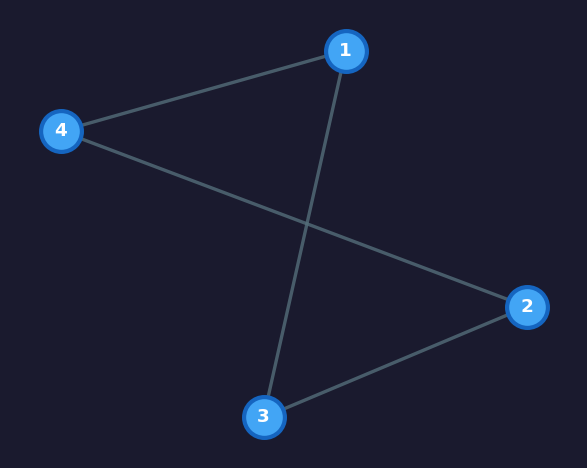
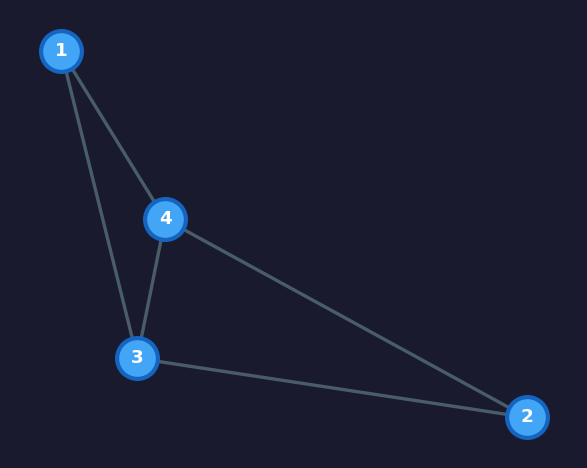
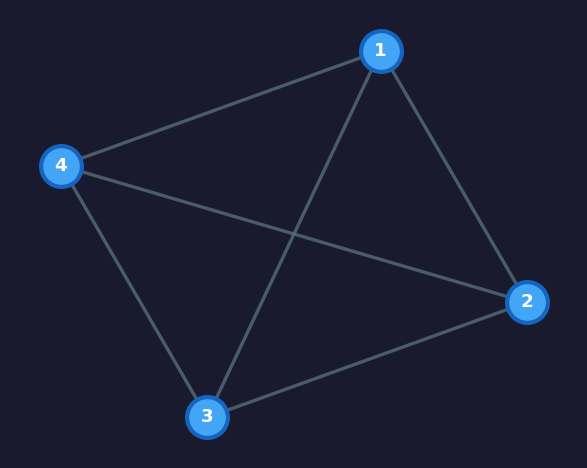

n = 5: D_1 holds for every graph (21 graphs analyzed).


Values of k,Graph,CDF static,CDF sequencial,Stochastic dominance
"[1, 4]",\n \n,"[0.5, 1.0]","[0.2, 1.0]",D_1 holds: the sequential model dominates the static model.
"[2, 3]",\n \n,"[0.333333, 1.0]","[0.266667, 1.0]",D_1 holds: the sequential model dominates the static model.
"[1, 3]",\n \n,"[0.333333, 1.0]","[0.2, 1.0]",D_1 holds: the sequential model dominates the static model.
"[2, 3]",\n \n,"[0.666667, 1.0]","[0.466667, 1.0]",D_1 holds: the sequential model dominates the static model.
"[2, 3]",\n \n,"[0.666667, 1.0]","[0.533333, 1.0]",D_1 holds: the sequential model dominates the static model.
"[1, 2, 3]",\n \n,"[0.333333, 0.666667, 1.0]","[0.2, 0.466667, 1.0]",D_1 holds: the sequential model dominates the static model.
"[2, 3]",\n \n,"[0.5, 1.0]","[0.4, 1.0]",D_1 holds: the sequential model dominates the static model.
"[1, 3]",\n \n,"[0.666667, 1.0]","[0.4, 1.0]",D_1 holds: the sequential model dominates the static model.
"[2, 3]",\n \n,"[0.75, 1.0]","[0.533333, 1.0]",D_1 holds: the sequential model dominates the static model.
[2],\n \n,[1.0],[1.0],Both cumulative distributions coincide (D_1 and D_2 both hold).

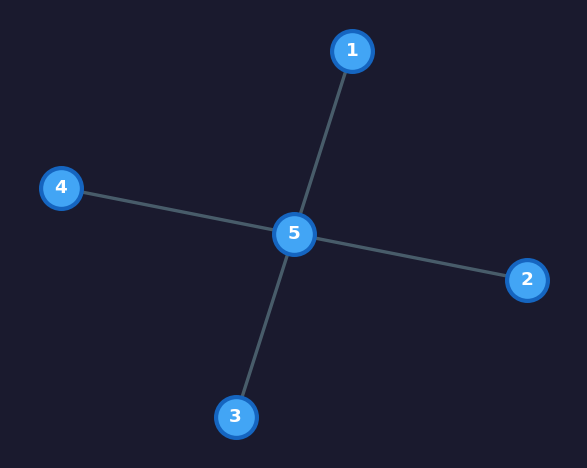
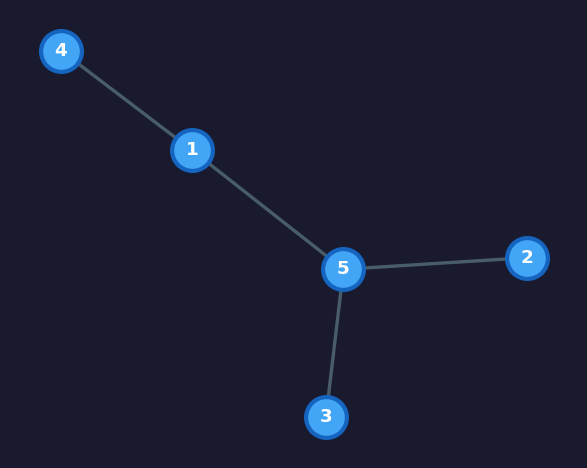
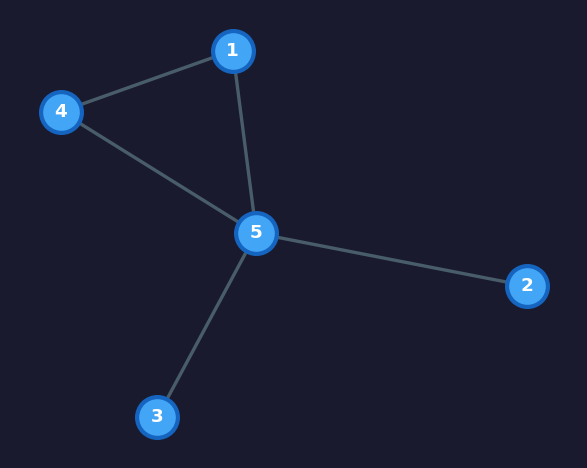
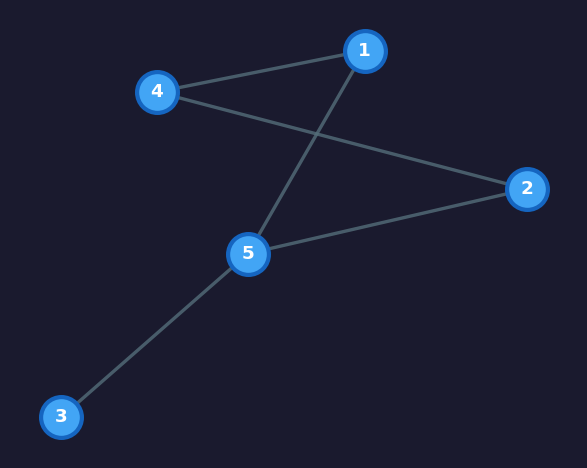
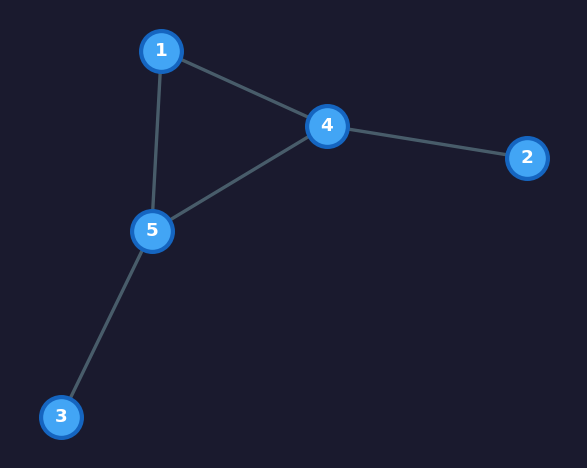
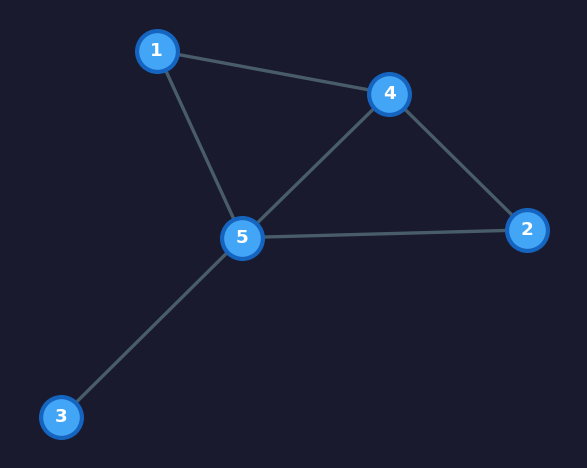
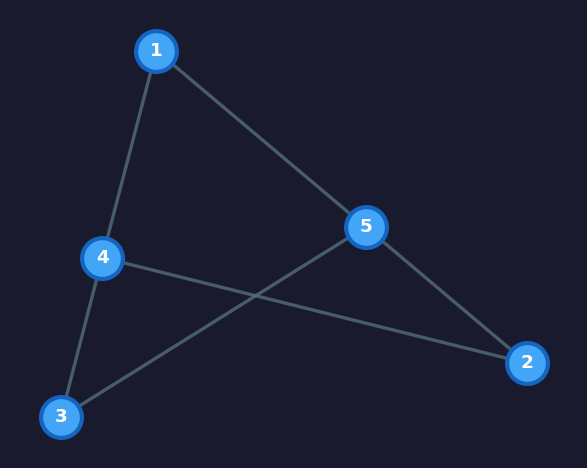
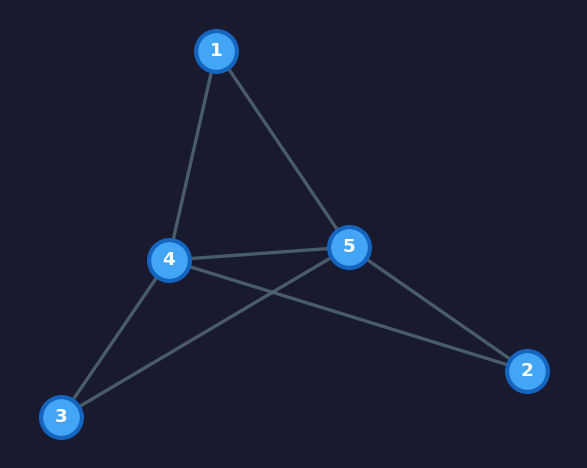
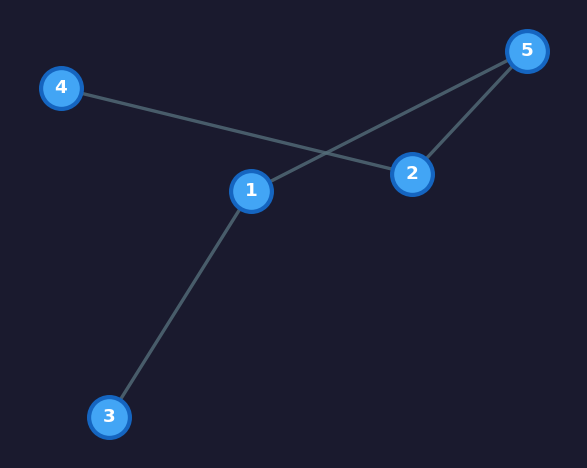
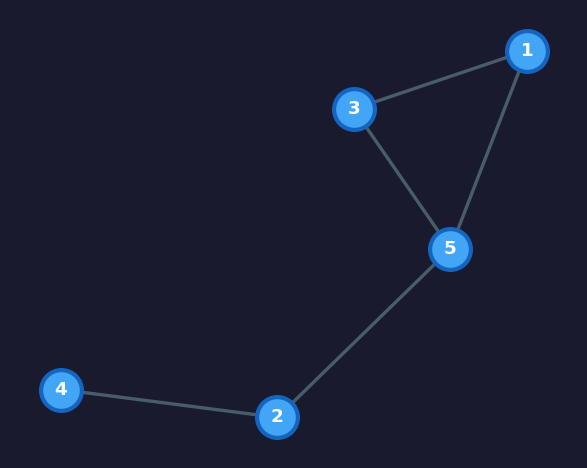
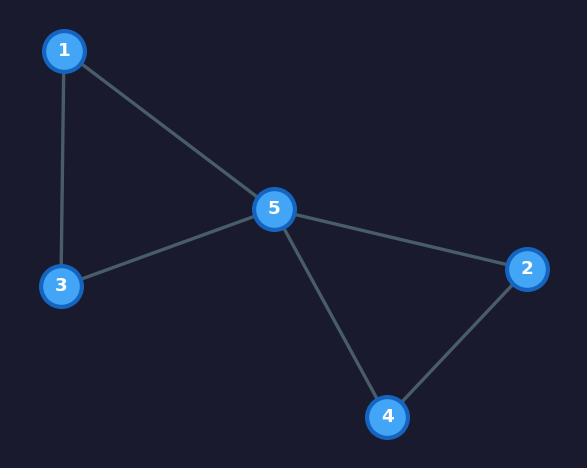
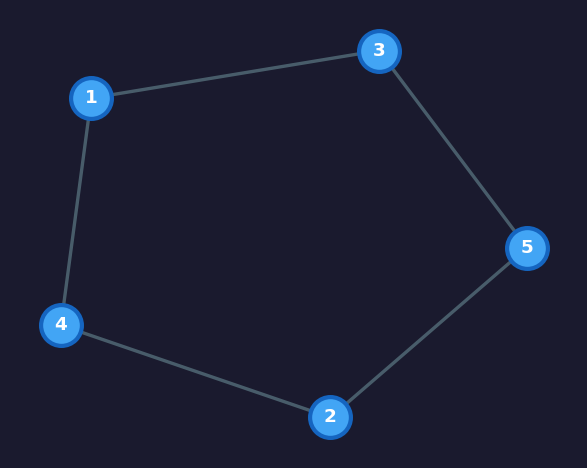
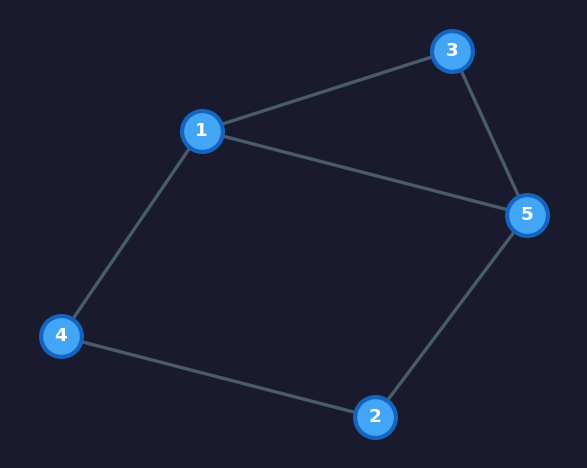
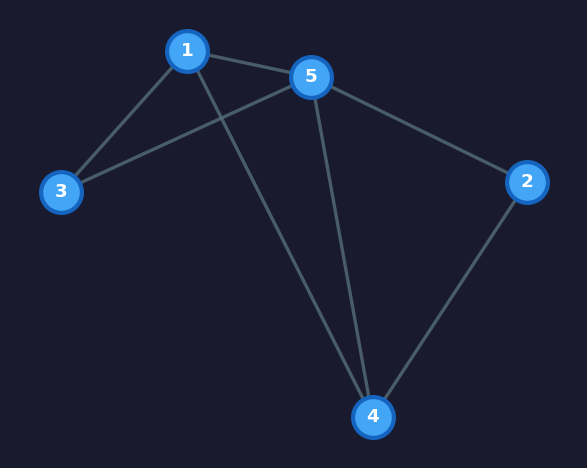
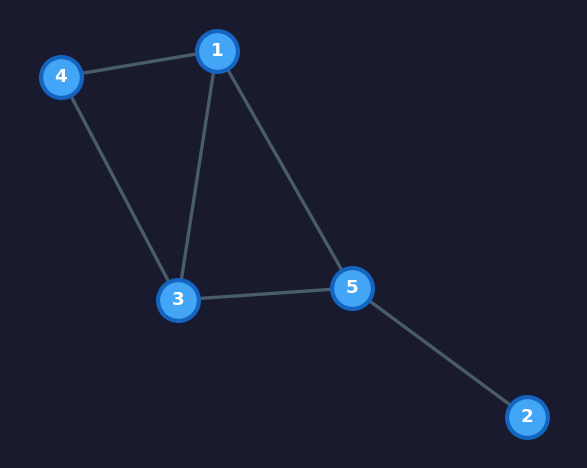
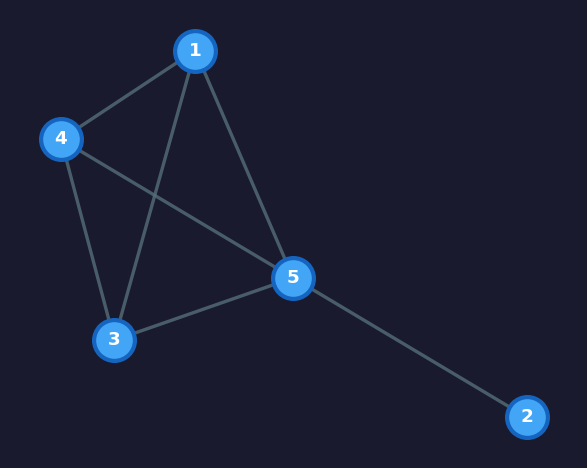
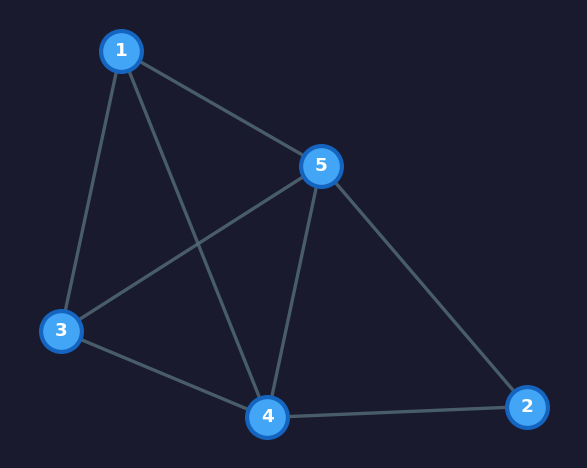
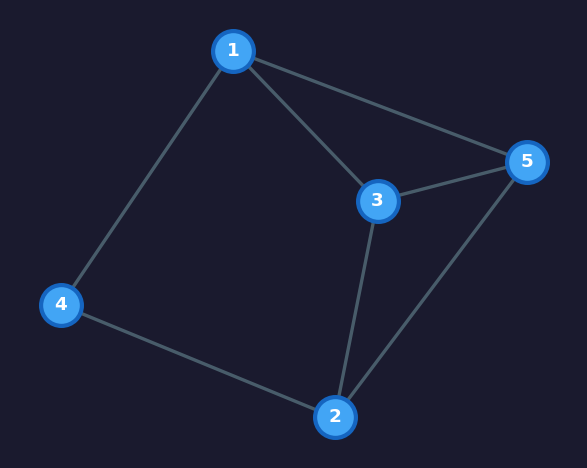
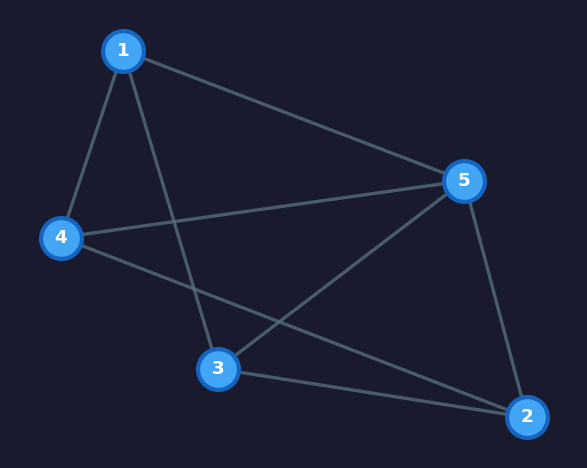
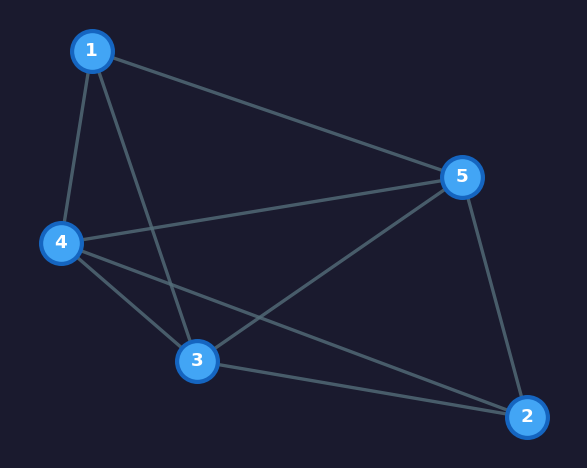
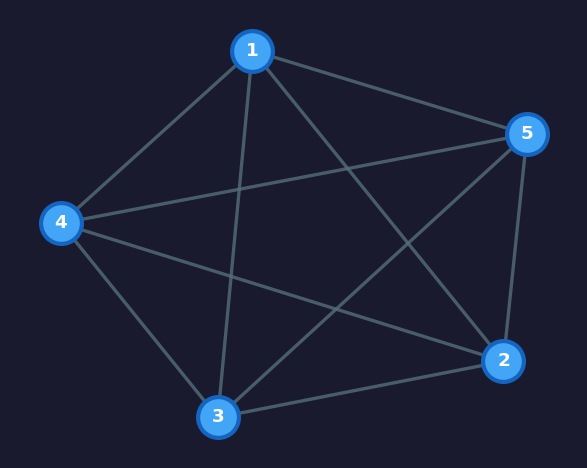


D_1 holds for every graph on up to 5 vertices.


In [ ]:
all_hold_small = True

for n in range(1, 6):
    result = find_first_dominance_failure(n, mode=0)
    failure = result["first_failure"]

    if failure is None:
        print(f"n = {n}: D_1 holds for every graph "
              f"({result['total']} graphs analyzed).")

       
        graphs = list(generate_symmetric_matrices(n))
        empty_titles = ["" for _ in graphs] 

        df = compare_graphs_table(graphs, empty_titles)
    else:
        all_hold_small = False
        print(f"n = {n}: D_1 FAILS for a graph with adjacency matrix:")
        for row in failure["adjacency_matrix"]:
            print(f"  {row}")

print()
if all_hold_small:
    print("D_1 holds for every graph on up to 5 vertices.")
else:
    print("D_1 does not hold for every graph on up to 5 vertices.")

## General search: D_1 or D_2 across all graphs up to n = 7

Checks, for every n from 1 to 7, whether any connected graph on n vertices
fails both D_1 and D_2. If `find_first_dominance_failure` returns `None` for every n,
D_1 or D_2 holds across the entire family.

In [15]:
all_hold_small = True

for n in range(1, 8):
    result = find_first_dominance_failure(n, mode=2)
    failure = result["first_failure"]

    # Contadores de este n
    print(f"n = {n}: {result['total']} graphs analyzed")
    print(f"  Same distribution (D_1 and D_2): {result['same_distribution']}")
    print(f"  Only D_1 holds:                  {result['only_D1']}")
    print(f"  Only D_2 holds:                  {result['only_D2']}")
    print(f"  Crossings (neither):             {result['crossing']}")

    if failure is None:
        print(f"  -> D_1 or D_2 holds for every graph.")
    else:
        all_hold_small = False
        print(f"  -> both D_1 and D_2 FAIL for a graph with adjacency matrix:")
        for row in failure["adjacency_matrix"]:
            print(f"     {row}")
    print()

if all_hold_small:
    print("D_1 or D_2 holds for every graph on up to 7 vertices.")
else:
    print("D_1 or D_2 does not hold for every graph on up to 7 vertices.")

n = 1: 1 graphs analyzed
  Same distribution (D_1 and D_2): 1
  Only D_1 holds:                  0
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 or D_2 holds for every graph.

n = 2: 1 graphs analyzed
  Same distribution (D_1 and D_2): 1
  Only D_1 holds:                  0
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 or D_2 holds for every graph.

n = 3: 2 graphs analyzed
  Same distribution (D_1 and D_2): 1
  Only D_1 holds:                  1
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 or D_2 holds for every graph.

n = 4: 6 graphs analyzed
  Same distribution (D_1 and D_2): 3
  Only D_1 holds:                  3
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 or D_2 holds for every graph.

n = 5: 21 graphs analyzed
  Same distribution (D_1 and D_2): 7
  Only D_1 holds:                  14
  Only D_2 holds:                  0
  Crossing

## General search: D_1 for max-degree-3 graphs up to n = 13

Same check, restricted to graphs with maximum degree at most 3, for n from
1 to 10.

In [ ]:
all_hold_bounded = True

for n in range(1, 13):
    result = find_first_dominance_failure(n, mode=0, max_degree=3)
    failure = result["first_failure"]

    # Contadores de este n
    print(f"n = {n}: {result['total']} graphs analyzed (max degree <= 3)")
    print(f"  Same distribution (D_1 and D_2): {result['same_distribution']}")
    print(f"  Only D_1 holds:                  {result['only_D1']}")
    print(f"  Only D_2 holds:                  {result['only_D2']}")
    print(f"  Crossings (neither):             {result['crossing']}")

    if failure is None:
        print(f"  -> D_1 holds for every graph with max degree <= 3.")
    else:
        all_hold_bounded = False
        print(f"  -> D_1 FAILS for a graph with adjacency matrix:")
        for row in failure["adjacency_matrix"]:
            print(f"     {row}")
    print()

if all_hold_bounded:
    print("D_1 holds for every graph on up to 12 vertices with max degree 3.")
else:
    print("D_1 does not hold for every graph on up to 12 vertices with max degree 3.")

n = 1: 1 graphs analyzed (max degree <= 3)
  Same distribution (D_1 and D_2): 1
  Only D_1 holds:                  0
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 holds for every graph with max degree <= 3.

n = 2: 1 graphs analyzed (max degree <= 3)
  Same distribution (D_1 and D_2): 1
  Only D_1 holds:                  0
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 holds for every graph with max degree <= 3.

n = 3: 2 graphs analyzed (max degree <= 3)
  Same distribution (D_1 and D_2): 1
  Only D_1 holds:                  1
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 holds for every graph with max degree <= 3.

n = 4: 6 graphs analyzed (max degree <= 3)
  Same distribution (D_1 and D_2): 3
  Only D_1 holds:                  3
  Only D_2 holds:                  0
  Crossings (neither):             0
  -> D_1 holds for every graph with max degree <= 3.

n = 5: 10 graphs ana

## Especial graphs

Values of k,Graph,CDF static,CDF sequencial,Stochastic dominance
"[2, 3, 4]",\n \n,"[0.111111, 0.555556, 1.0]","[0.15, 0.416667, 1.0]",Neither D_1 nor D_2 holds: the cumulative distributions cross.
"[3, 4, 5]",\n \n,"[0.055556, 0.555556, 1.0]","[0.057143, 0.447619, 1.0]",Neither D_1 nor D_2 holds: the cumulative distributions cross.
"[2, 3]",\n \n,"[0.111111, 1.0]","[0.171429, 1.0]",D_2 holds: the static model dominates the sequential model.
"[1, 2]",\n \n,"[0.5, 1.0]","[0.333333, 1.0]",D_1 holds: the sequential model dominates the static model.
"[4, 5, 6]",\n \n,"[0.066667, 0.466667, 1.0]","[0.07619, 0.47619, 1.0]",D_2 holds: the static model dominates the sequential model.
"[2, 3]",\n \n,"[0.333333, 1.0]","[0.266667, 1.0]",D_1 holds: the sequential model dominates the static model.
"[2, 3]",\n \n,"[0.2, 1.0]","[0.285714, 1.0]",D_2 holds: the static model dominates the sequential model.
"[3, 4, 5]",\n \n,"[0.1, 0.6, 1.0]","[0.069444, 0.472222, 1.0]",D_1 holds: the sequential model dominates the static model.
"[2, 3]",\n \n,"[0.2, 1.0]","[0.208333, 1.0]",D_2 holds: the static model dominates the sequential model.
"[1, 2]",\n \n,"[0.5, 1.0]","[0.333333, 1.0]",D_1 holds: the sequential model dominates the static model.

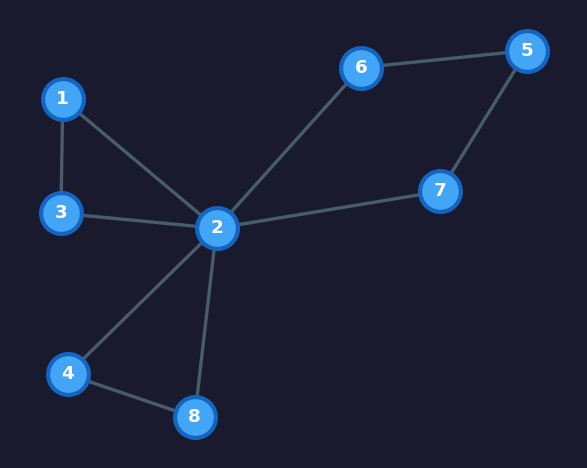
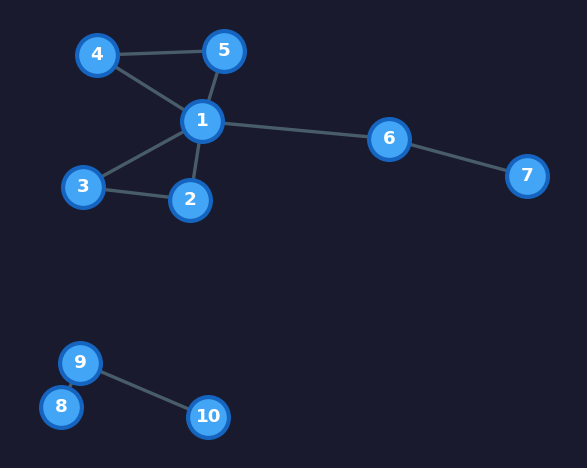
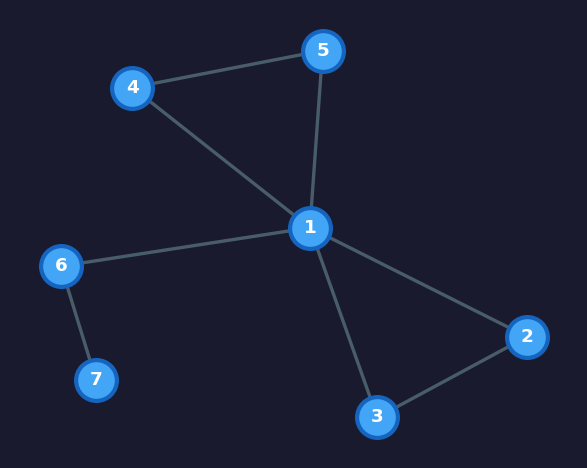
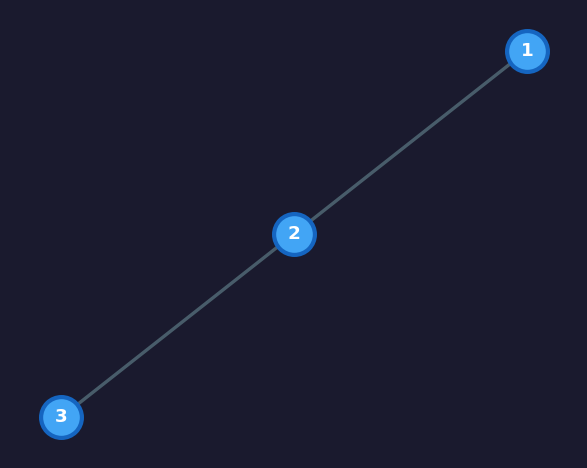
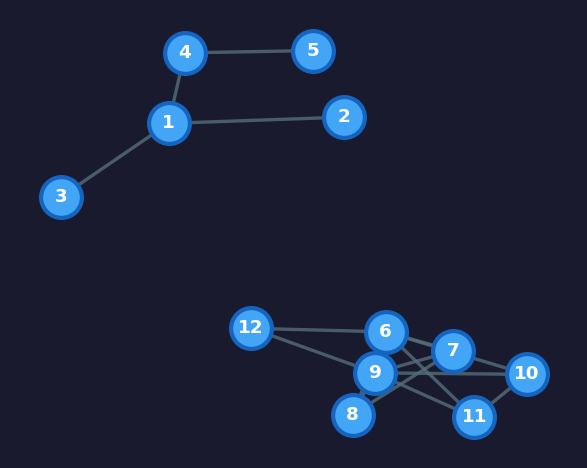
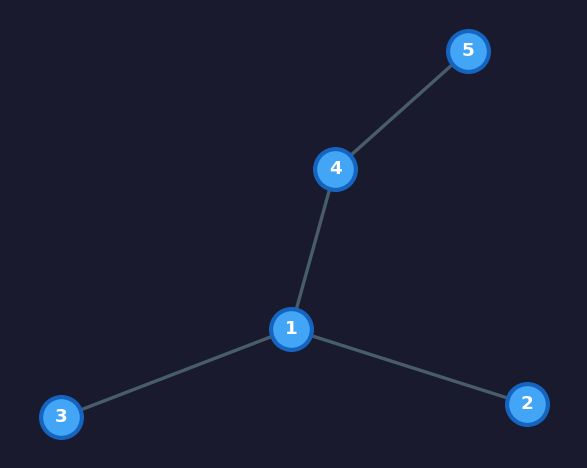
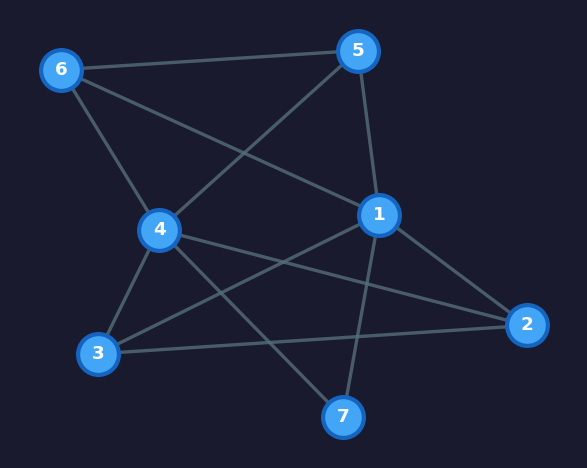
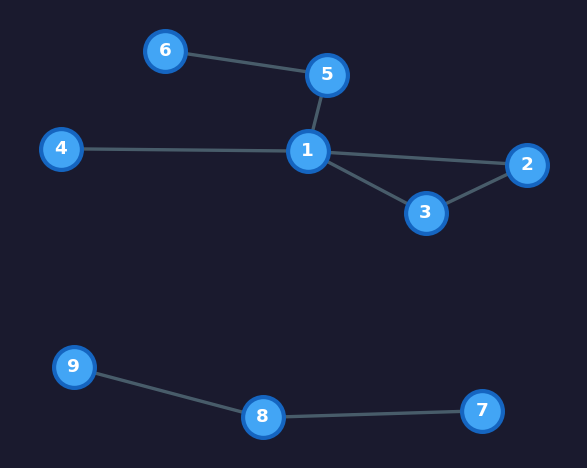
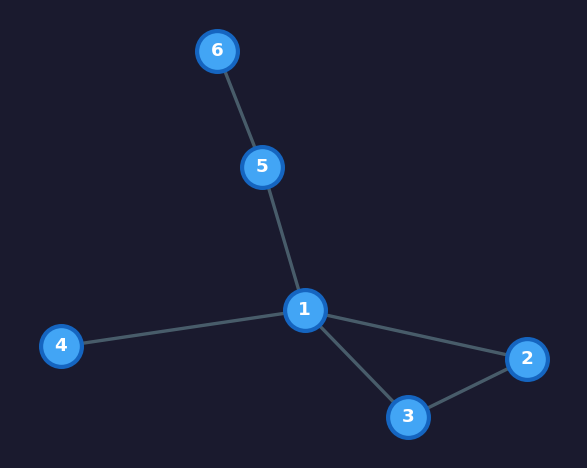
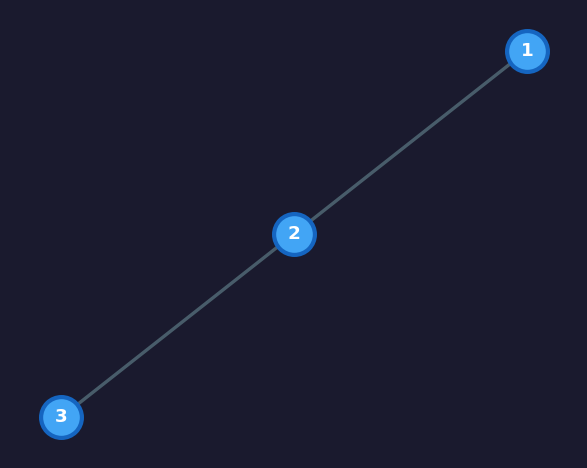

In [17]:


G1 = [
    [0,1,1,0,0,0,0,0],
    [1,0,1,1,0,1,1,1],
    [1,1,0,0,0,0,0,0],
    [0,1,0,0,0,0,0,1],
    [0,0,0,0,0,1,1,0],
    [0,1,0,0,1,0,0,0],
    [0,1,0,0,1,0,0,0],
    [0,1,0,1,0,0,0,0]
]



G2 = [
    [0,1,1,1,1,1,0,0,0,0],
    [1,0,1,0,0,0,0,0,0,0],
    [1,1,0,0,0,0,0,0,0,0],
    [1,0,0,0,1,0,0,0,0,0],
    [1,0,0,1,0,0,0,0,0,0],
    [1,0,0,0,0,0,1,0,0,0],
    [0,0,0,0,0,1,0,0,0,0],
    [0,0,0,0,0,0,0,0,1,0],
    [0,0,0,0,0,0,0,1,0,1],
    [0,0,0,0,0,0,0,0,1,0]
]

G2_comp1 = [
    [0,1,1,1,1,1,0],
    [1,0,1,0,0,0,0],
    [1,1,0,0,0,0,0],
    [1,0,0,0,1,0,0],
    [1,0,0,1,0,0,0],
    [1,0,0,0,0,0,1],
    [0,0,0,0,0,1,0]
]

G2_comp2 = [
    [0,1,0],
    [1,0,1],
    [0,1,0]
]



G3 = [
    [0,1,1,1,0,0,0,0,0,0,0,0],
    [1,0,0,0,0,0,0,0,0,0,0,0],
    [1,0,0,0,0,0,0,0,0,0,0,0],
    [1,0,0,0,1,0,0,0,0,0,0,0],
    [0,0,0,1,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,1,1,0,1,1,1],
    [0,0,0,0,0,1,0,1,1,0,0,0],
    [0,0,0,0,0,1,1,0,1,0,0,0],
    [0,0,0,0,0,0,1,1,0,1,1,1],
    [0,0,0,0,0,1,0,0,1,0,1,0],
    [0,0,0,0,0,1,0,0,1,1,0,0],
    [0,0,0,0,0,1,0,0,1,0,0,0]
]

G3_comp1 = [
    [0,1,1,1,0],
    [1,0,0,0,0],
    [1,0,0,0,0],
    [1,0,0,0,1],
    [0,0,0,1,0]
]

G3_comp2 = [
    [0,1,1,0,1,1,1],
    [1,0,1,1,0,0,0],
    [1,1,0,1,0,0,0],
    [0,1,1,0,1,1,1],
    [1,0,0,1,0,1,0],
    [1,0,0,1,1,0,0],
    [1,0,0,1,0,0,0]
]



G4 = [
    [0,1,1,1,1,0,0,0,0],
    [1,0,1,0,0,0,0,0,0],
    [1,1,0,0,0,0,0,0,0],
    [1,0,0,0,0,0,0,0,0],
    [1,0,0,0,0,1,0,0,0],
    [0,0,0,0,1,0,0,0,0],
    [0,0,0,0,0,0,0,1,0],
    [0,0,0,0,0,0,1,0,1],
    [0,0,0,0,0,0,0,1,0]
]

G4_comp1 = [
    [0,1,1,1,1,0],
    [1,0,1,0,0,0],
    [1,1,0,0,0,0],
    [1,0,0,0,0,0],
    [1,0,0,0,0,1],
    [0,0,0,0,1,0]
]

G4_comp2 = [
    [0,1,0],
    [1,0,1],
    [0,1,0]
]

df = compare_graphs_table(
    [G1, G2, G2_comp1,G2_comp2, G3,G3_comp1,G3_comp2, G4,G4_comp1,G4_comp2], ["","","","","","","","","",""])